**JPEG Encoder**

Batch encode and comparison


[1] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Gradient_sq_gray.png -> stem=Gradient_sq_gray


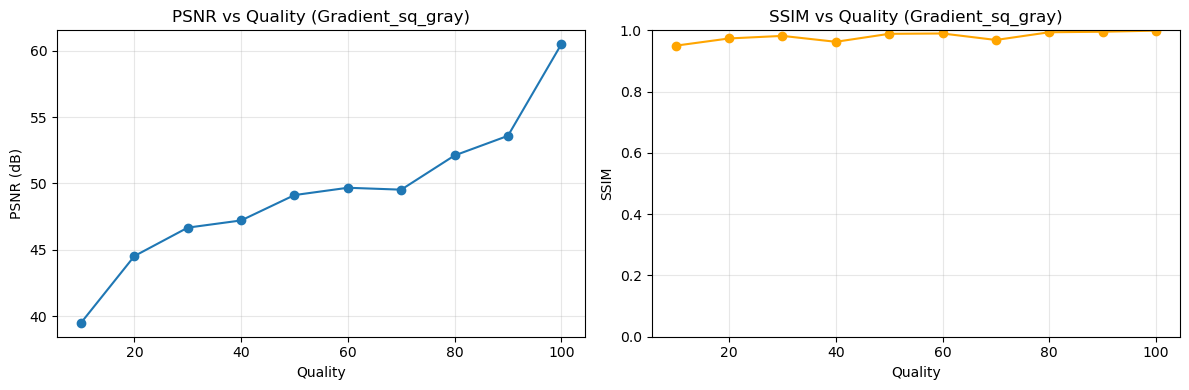

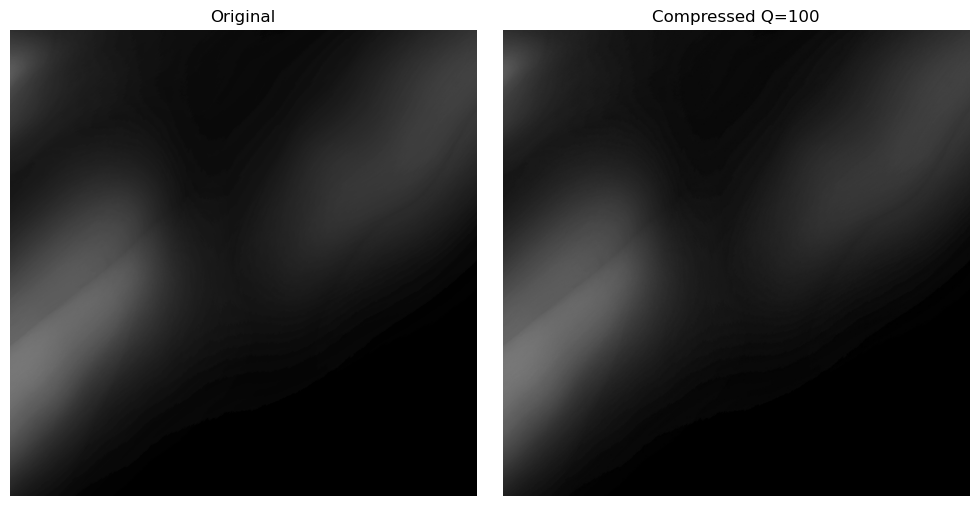

Saved original PNG: Gradient_sq_gray_orig.png (315.9 KB)
Saved compressed JPG: Gradient_sq_gray_JPEG_Q100.jpg (272.1 KB)
JPEG/PNG size ratio: 0.861
At Q=100: PSNR=60.48 dB, SSIM=0.9991

[2] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Grass_sq_gray.png -> stem=Grass_sq_gray


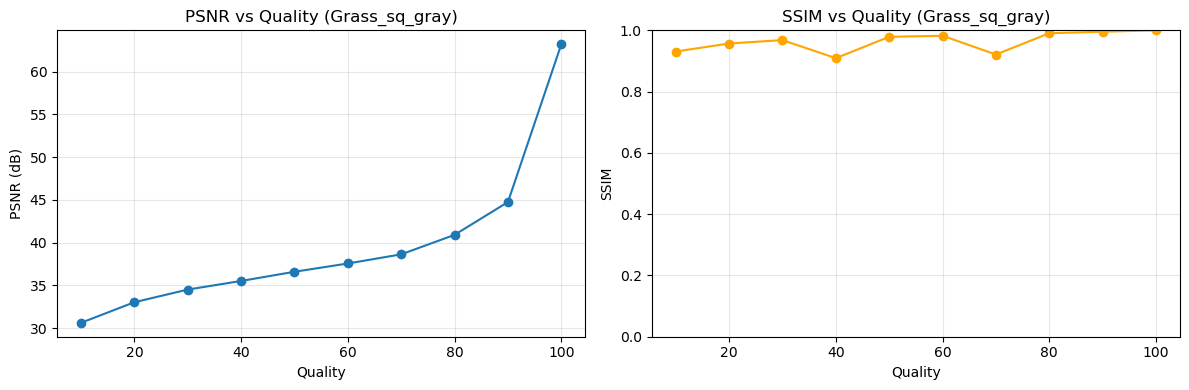

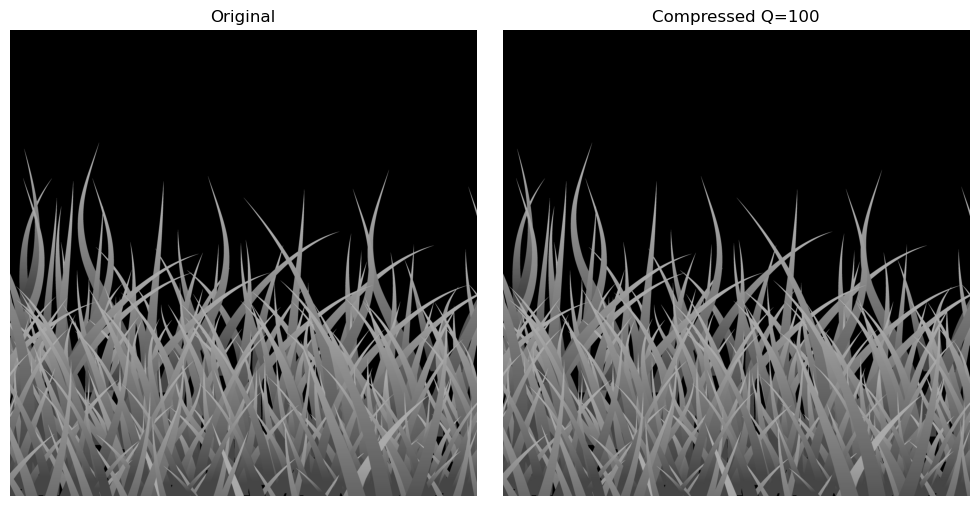

Saved original PNG: Grass_sq_gray_orig.png (311.9 KB)
Saved compressed JPG: Grass_sq_gray_JPEG_Q100.jpg (451.2 KB)
JPEG/PNG size ratio: 1.446
At Q=100: PSNR=63.21 dB, SSIM=0.9999

[3] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Mixed_sq_gray.png -> stem=Mixed_sq_gray


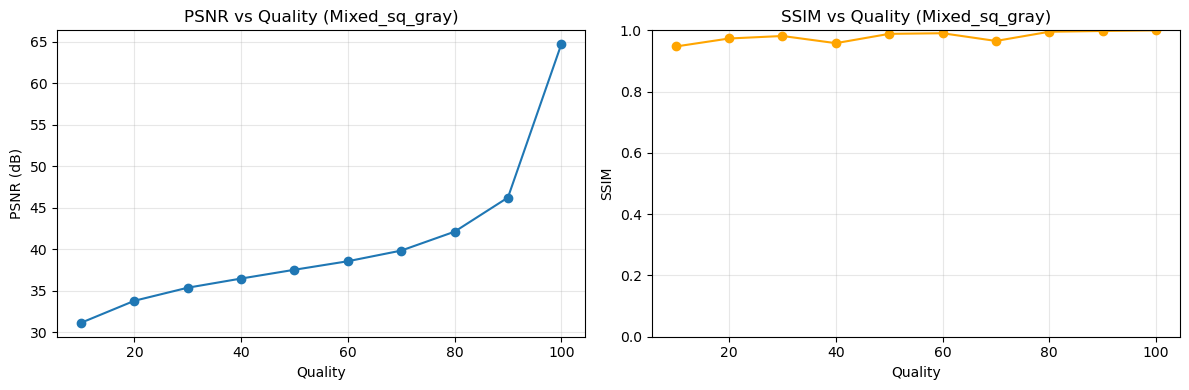

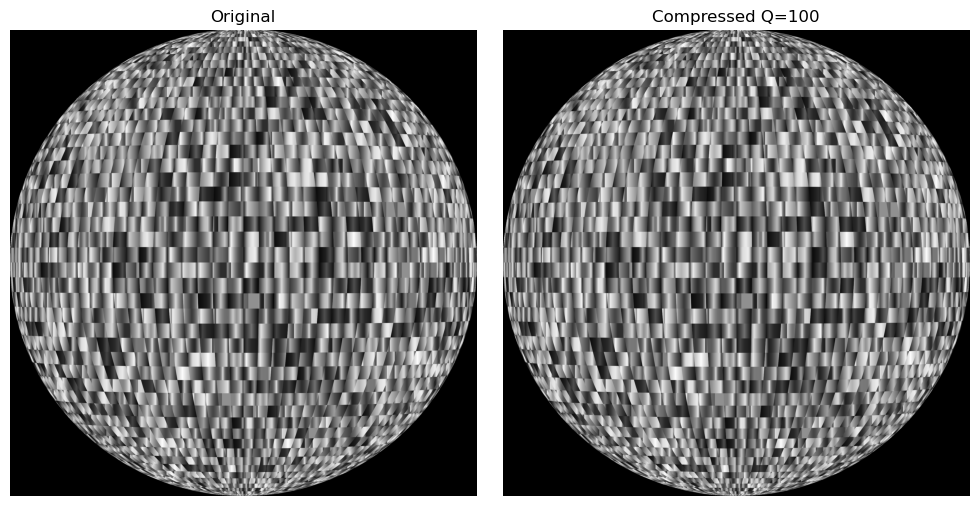

Saved original PNG: Mixed_sq_gray_orig.png (710.5 KB)
Saved compressed JPG: Mixed_sq_gray_JPEG_Q100.jpg (1.23 MB)
JPEG/PNG size ratio: 1.778
At Q=100: PSNR=64.73 dB, SSIM=1.0000

[4] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Nature_sq_gray.png -> stem=Nature_sq_gray


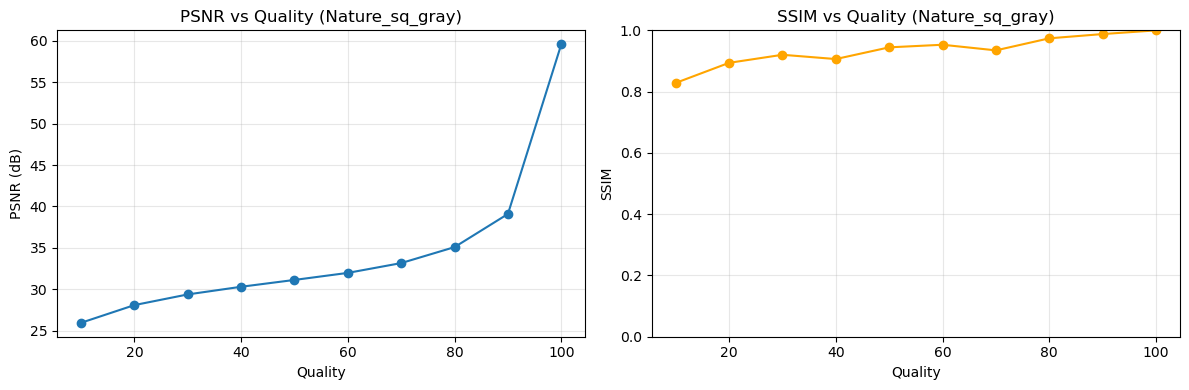

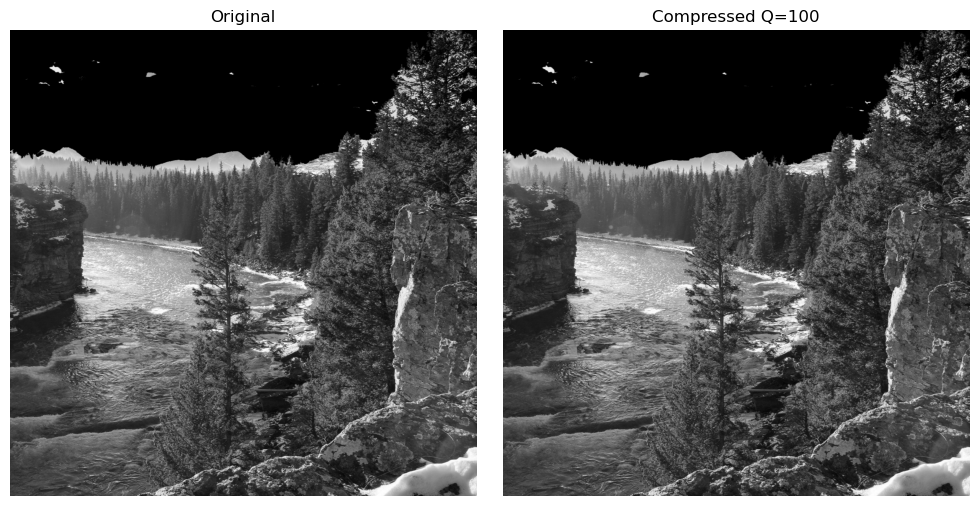

Saved original PNG: Nature_sq_gray_orig.png (1.29 MB)
Saved compressed JPG: Nature_sq_gray_JPEG_Q100.jpg (859.4 KB)
JPEG/PNG size ratio: 0.649
At Q=100: PSNR=59.57 dB, SSIM=0.9998

[5] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\SharpEdges_sq_gray.png -> stem=SharpEdges_sq_gray


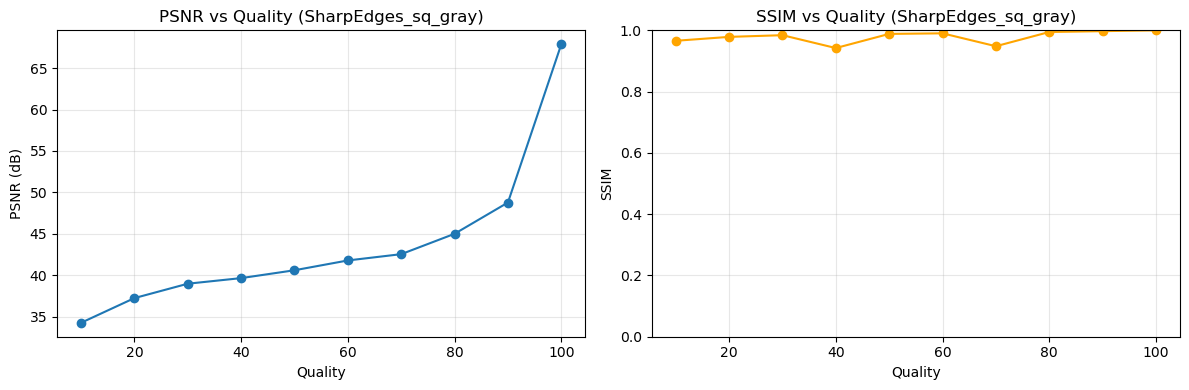

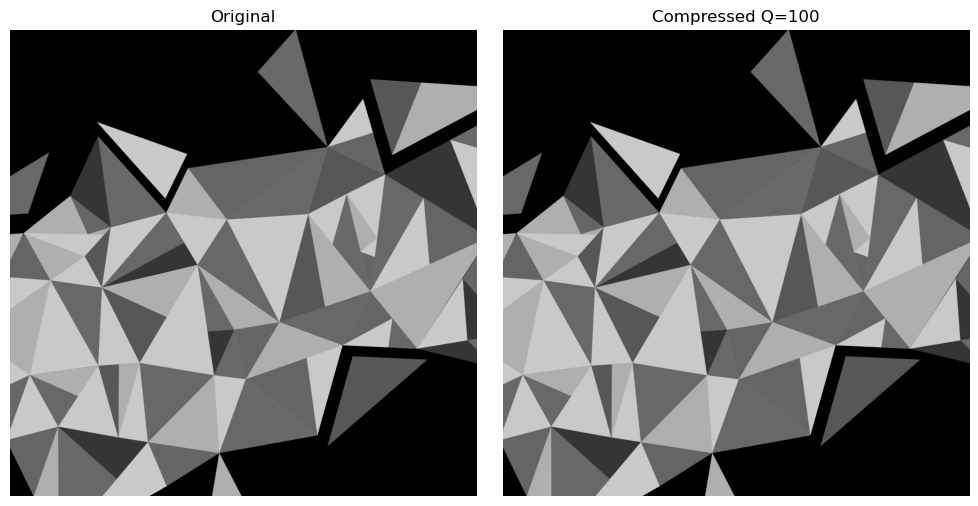

Saved original PNG: SharpEdges_sq_gray_orig.png (135.9 KB)
Saved compressed JPG: SharpEdges_sq_gray_JPEG_Q100.jpg (231.7 KB)
JPEG/PNG size ratio: 1.706
At Q=100: PSNR=67.88 dB, SSIM=1.0000

All done.


In [1]:
# Batch encode + compare: fill the five paths below (or leave blank to skip a slot).
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import io

# --- User: replace these with your image file paths (up to 5) ---
image_paths = [
    r"C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Gradient_sq_gray.png",
    r"C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Grass_sq_gray.png",
    r"C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Mixed_sq_gray.png",
    r"C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Nature_sq_gray.png",
    r"C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\SharpEdges_sq_gray.png"
]

# --- Helpers: PSNR / SSIM (same algorithm as in Code.ipynb) ---
import math

def psnr(img1, img2, data_range=255.0):
    x = img1.astype(np.float64)
    y = img2.astype(np.float64)
    mse = np.mean((x - y) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * np.log10(data_range) - 10 * np.log10(mse)

def _box_filter_same(img, w):
    if img.ndim == 2:
        img = img[..., None]
        squeeze = True
    else:
        squeeze = False
    pad = w // 2
    img_p = np.pad(img, ((pad, pad), (pad, pad), (0, 0)), mode='reflect')
    tmp = np.cumsum(img_p, axis=0)
    tmp = tmp[w:, :, :] - tmp[:-w, :, :]
    tmp2 = np.cumsum(tmp, axis=1)
    res = tmp2[:, w:, :] - tmp2[:, :-w, :]
    res = res / (w * w)
    if squeeze:
        return res[..., 0]
    return res

def ssim(img1, img2, data_range=255.0, win_size=11, K1=0.01, K2=0.03):
    x = img1.astype(np.float64)
    y = img2.astype(np.float64)
    C1 = (K1 * data_range) ** 2
    C2 = (K2 * data_range) ** 2
    mu_x = _box_filter_same(x, win_size)
    mu_y = _box_filter_same(y, win_size)
    sigma_x2 = _box_filter_same(x * x, win_size) - mu_x * mu_x
    sigma_y2 = _box_filter_same(y * y, win_size) - mu_y * mu_y
    sigma_xy = _box_filter_same(x * y, win_size) - mu_x * mu_y
    num = (2 * mu_x * mu_y + C1) * (2 * sigma_xy + C2)
    den = (mu_x * mu_x + mu_y * mu_y + C1) * (sigma_x2 + sigma_y2 + C2)
    ssim_map = num / (den + 1e-12)
    return float(np.mean(ssim_map))

# --- Processing parameters ---
qualities = list(range(10, 101, 10))  # 10..100 step 10
chosen_quality = 100  # saved compressed image quality (set to 100 + subsampling=0 for minimal loss)
subsamp = 0  # 0=no chroma subsampling (4:4:4)

# utility for human file sizes
def fmt_bytes(b):
    if b is None:
        return 'N/A'
    if b < 1024:
        return f"{b} B"
    kb = b / 1024.0
    if kb < 1024:
        return f"{kb:.1f} KB"
    mb = kb / 1024.0
    return f"{mb:.2f} MB"

# --- Run over image slots ---
for idx, p in enumerate(image_paths):
    if not p:
        continue
    path = Path(p)
    if not path.exists():
        print(f"[{idx+1}] Path not found: {p}")
        continue

    stem = path.stem
    print('\n' + '='*60)
    print(f"[{idx+1}] Processing: {path} -> stem={stem}")

    pil = Image.open(path).convert('RGB')
    orig = np.array(pil, dtype=np.uint8)

    psnrs = []
    ssims = []

    # Sweep qualities and compute metrics
    for q in qualities:
        # compress into memory to avoid writing many files
        buf = io.BytesIO()
        pil.save(buf, format='JPEG', quality=q, subsampling=subsamp, optimize=True)
        buf.seek(0)
        rec = np.array(Image.open(buf).convert('RGB'), dtype=np.uint8)
        psnrs.append(psnr(orig, rec))
        ssims.append(ssim(orig, rec))

    # Plot PSNR/SSIM curves
    fig, ax = plt.subplots(1,2, figsize=(12,4))
    ax[0].plot(qualities, psnrs, marker='o')
    ax[0].set_title(f'PSNR vs Quality ({stem})')
    ax[0].set_xlabel('Quality')
    ax[0].set_ylabel('PSNR (dB)')
    ax[0].grid(True, alpha=0.3)

    ax[1].plot(qualities, ssims, marker='o', color='orange')
    ax[1].set_title(f'SSIM vs Quality ({stem})')
    ax[1].set_xlabel('Quality')
    ax[1].set_ylabel('SSIM')
    ax[1].set_ylim(0, 1.0)
    ax[1].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Save compressed image at chosen_quality to disk
    out_jpg = f"{stem}_JPEG_Q{chosen_quality}.jpg"
    pil.save(out_jpg, format='JPEG', quality=chosen_quality, subsampling=subsamp, optimize=True)

    # Save original as PNG for size comparison
    out_png = f"{stem}_orig.png"
    Image.fromarray(orig).save(out_png, format='PNG', optimize=True)

    # Get sizes
    try:
        size_png = Path(out_png).stat().st_size
    except Exception:
        size_png = None
    try:
        size_jpg = Path(out_jpg).stat().st_size
    except Exception:
        size_jpg = None

    # Reconstruct compressed for display
    rec = np.array(Image.open(out_jpg).convert('RGB'), dtype=np.uint8)

    # Display side-by-side
    fig2, ax2 = plt.subplots(1,2, figsize=(10,5))
    ax2[0].imshow(orig); ax2[0].set_title('Original'); ax2[0].axis('off')
    ax2[1].imshow(rec); ax2[1].set_title(f'Compressed Q={chosen_quality}'); ax2[1].axis('off')
    plt.tight_layout()
    plt.show()

    # Print sizes and PSNR/SSIM at chosen quality
    psnr_chosen = psnr(orig, rec)
    ssim_chosen = ssim(orig, rec)
    print(f"Saved original PNG: {out_png} ({fmt_bytes(size_png)})")
    print(f"Saved compressed JPG: {out_jpg} ({fmt_bytes(size_jpg)})")
    if size_png and size_jpg:
        print(f"JPEG/PNG size ratio: {size_jpg/size_png:.3f}")
    print(f"At Q={chosen_quality}: PSNR={psnr_chosen:.2f} dB, SSIM={ssim_chosen:.4f}")

print('\nAll done.')


In [3]:
# --- JPEG encoding time vs quality with PSNR/SSIM ---
import time
import pandas as pd

encoding_stats = {}

for idx, p in enumerate(image_paths):
    if not p:
        continue
    path = Path(p)
    if not path.exists():
        print(f"[{idx+1}] Path not found: {p}")
        continue

    stem = path.stem
    pil = Image.open(path).convert('RGB')
    orig = np.array(pil, dtype=np.uint8)

    records = []
    for q in qualities:
        buf = io.BytesIO()
        start = time.perf_counter()
        pil.save(buf, format='JPEG', quality=q, subsampling=subsamp, optimize=True)
        elapsed = time.perf_counter() - start
        buf.seek(0)
        rec = np.array(Image.open(buf).convert('RGB'), dtype=np.uint8)

        psnr_val = psnr(orig, rec)
        ssim_val = ssim(orig, rec)

        records.append({
            'Quality': q,
            'Encode Time (s)': elapsed,
            'PSNR (dB)': psnr_val,
            'SSIM': ssim_val
        })

    df = pd.DataFrame(records)
    encoding_stats[stem] = df
    display(
        df.style
          .format({'Encode Time (s)': '{:.4f}', 'PSNR (dB)': '{:.2f}', 'SSIM': '{:.4f}'})
          .set_caption(f'JPEG encode metrics vs quality ({stem})')
    )

,Quality,Encode Time (s),PSNR (dB),SSIM
0,10,0.0498,39.50,0.9499
1,20,0.0450,44.53,0.9735
2,30,0.0502,46.67,0.9819
3,40,0.0461,47.21,0.9626
4,50,0.0483,49.12,0.9886
5,60,0.0474,49.67,0.9897
6,70,0.0357,49.53,0.9686
7,80,0.0411,52.11,0.9937
8,90,0.0491,53.59,0.9954
9,100,0.0934,60.48,0.9991


,Quality,Encode Time (s),PSNR (dB),SSIM
0,10,0.0396,30.62,0.9309
1,20,0.0413,33.03,0.9570
2,30,0.0399,34.51,0.9682
3,40,0.0443,35.51,0.9091
4,50,0.0443,36.59,0.9788
5,60,0.0483,37.56,0.9823
6,70,0.0537,38.63,0.9211
7,80,0.0456,40.91,0.9905
8,90,0.0459,44.75,0.9955
9,100,0.0616,63.21,0.9999


,Quality,Encode Time (s),PSNR (dB),SSIM
0,10,0.1145,31.15,0.9472
1,20,0.2059,33.80,0.9734
2,30,0.1580,35.38,0.9815
3,40,0.1653,36.48,0.9581
4,50,0.1655,37.54,0.9885
5,60,0.1446,38.57,0.9905
6,70,0.2324,39.85,0.9654
7,80,0.2278,42.13,0.9954
8,90,0.2123,46.25,0.9979
9,100,0.1775,64.73,1.0000


,Quality,Encode Time (s),PSNR (dB),SSIM
0,10,0.0538,25.97,0.8284
1,20,0.0542,28.11,0.8939
2,30,0.0522,29.39,0.9202
3,40,0.0525,30.32,0.9063
4,50,0.0627,31.14,0.9445
5,60,0.0535,31.99,0.9530
6,70,0.0518,33.17,0.9346
7,80,0.0518,35.10,0.9739
8,90,0.0549,39.10,0.9878
9,100,0.0635,59.57,0.9998


,Quality,Encode Time (s),PSNR (dB),SSIM
0,10,0.0600,34.24,0.9659
1,20,0.0582,37.23,0.9786
2,30,0.0514,38.96,0.9842
3,40,0.0464,39.64,0.9422
4,50,0.0483,40.59,0.9884
5,60,0.0473,41.77,0.9902
6,70,0.0549,42.53,0.9481
7,80,0.0498,44.99,0.9945
8,90,0.0528,48.77,0.9973
9,100,0.0824,67.88,1.0000
